In [ ]:
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
torch.manual_seed(42); np.random.seed(42)

# downloading the dataset in colab
!gdown 1cRuq2ucZILOKfCn3Y7l4RJIVM7BJK0y-

Downloading...
From: https://drive.google.com/uc?id=1cRuq2ucZILOKfCn3Y7l4RJIVM7BJK0y-
To: /content/swiftlend.csv
100% 261k/261k [00:00<00:00, 75.5MB/s]


In [ ]:
df= pd.read_csv("/content/swiftlend.csv")

In [ ]:
df.head()

,age,monthly_income,loan_amount,credit_score,existing_emi,missed_payments,years_employed,city_tier,job_type,decision
0,57,19.2,220.0,614.0,5.2,2,31,Tier3,Salaried,Decline
1,45,36.5,487.0,670.0,7.4,0,19,Tier1,Self-employed,Review
2,47,19.9,170.0,701.0,3.6,0,22,Tier1,Salaried,Approve
3,55,50.9,199.0,685.0,11.4,0,30,Tier1,Self-employed,Approve
4,43,49.5,319.0,630.0,6.0,0,15,Tier1,Gig,Approve


In [ ]:
df.shape

(5000, 10)

In [ ]:
df['decision'].value_counts()

,count
decision,
Approve,2250
Decline,1400
Review,1350


In [ ]:
X=pd.get_dummies(df.drop(columns=['decision']), columns=['city_tier','job_type'], dtype=float)

In [ ]:
X

,age,monthly_income,loan_amount,credit_score,existing_emi,missed_payments,years_employed,city_tier_Tier1,city_tier_Tier2,city_tier_Tier3,job_type_Gig,job_type_Salaried,job_type_Self-employed
0,57,19.2,220.0,614.0,5.2,2,31,0.0,0.0,1.0,0.0,1.0,0.0
1,45,36.5,487.0,670.0,7.4,0,19,1.0,0.0,0.0,0.0,0.0,1.0
2,47,19.9,170.0,701.0,3.6,0,22,1.0,0.0,0.0,0.0,1.0,0.0
3,55,50.9,199.0,685.0,11.4,0,30,1.0,0.0,0.0,0.0,0.0,1.0
4,43,49.5,319.0,630.0,6.0,0,15,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,32,44.8,468.0,827.0,9.8,1,9,1.0,0.0,0.0,0.0,0.0,1.0
4996,34,56.4,177.0,759.0,21.5,0,11,1.0,0.0,0.0,1.0,0.0,0.0
4997,45,31.1,165.0,777.0,1.5,1,22,1.0,0.0,0.0,0.0,0.0,1.0
4998,29,60.7,612.0,719.0,12.0,0,7,1.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
y= df['decision'].map({"Approve":0, "Review":1, "Decline":2})

In [ ]:
Xtr, Xtmp, ytr, ytmp= train_test_split(X,y, test_size=0.4, stratify=y, random_state=42)
Xva, Xte, yva, yte= train_test_split(Xtmp,ytmp, test_size=0.5, stratify=ytmp, random_state=42)

In [ ]:
len(Xtr), len(Xva), len(Xte)

(3000, 1000, 1000)

In [ ]:
sc = StandardScaler()

# Fit on training data and transform
Xtr_s = sc.fit_transform(Xtr)
# Transform validation and test data
Xva_s =sc.transform(Xva)
Xte_s = sc.transform(Xte)

In [ ]:
Xtr_t = torch.tensor(Xtr_s, dtype=torch.float32)
Xva_t = torch.tensor(Xva_s, dtype=torch.float32)
Xte_t = torch.tensor(Xte_s, dtype=torch.float32)

print("Xtr_t shape:", Xtr_t.shape)
print("Xva_t shape:", Xva_t.shape)
print("Xte_t shape:", Xte_t.shape)

Xtr_t shape: torch.Size([3000, 13])
Xva_t shape: torch.Size([1000, 13])
Xte_t shape: torch.Size([1000, 13])


In [ ]:
ytr_t = torch.tensor(ytr.values, dtype=torch.long)
yva_t = torch.tensor(yva.values, dtype=torch.long)
yte_t = torch.tensor(yte.values, dtype=torch.long)

print("ytr_t shape:", ytr_t.shape)
print("yva_t shape:", yva_t.shape)
print("yte_t shape:", yte_t.shape)

ytr_t shape: torch.Size([3000])
yva_t shape: torch.Size([1000])
yte_t shape: torch.Size([1000])


In [ ]:
lr= LogisticRegression(max_iter=1000)
lr.fit(Xtr_s, ytr)

LogisticRegression(max_iter=1000)

In [ ]:
lr.score(Xva_s, yva)

0.784

In [ ]:
X.shape

(5000, 13)

In [ ]:
model = nn.Sequential(
    nn.Linear(13, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 3)
)



In [ ]:
[p.numel() for p in model.parameters()]

[1664, 128, 8192, 64, 192, 3]

In [ ]:
x = Xtr_t[:1]

In [ ]:
x

tensor([[-1.0155,  1.1922,  0.7735, -0.7421, -0.1050,  0.2197, -1.1881, -0.8319,
          1.3668, -0.5655,  1.9938, -1.1266, -0.5614]])

In [ ]:
z= model(x)

In [ ]:
z

tensor([[-0.0147,  0.0415, -0.0932]], grad_fn=<AddmmBackward0>)

In [ ]:
p=torch.softmax(z, dim=1) ##### remember this --- this is before traininig

print(p)

tensor([[0.3353, 0.3547, 0.3100]], grad_fn=<SoftmaxBackward0>)


In [ ]:
by_hand= - torch.log(p[0, ytr_t[0]])

In [ ]:
by_torch= nn.CrossEntropyLoss()(z, ytr_t[:1])

In [ ]:
by_torch

tensor(1.1712, grad_fn=<NllLossBackward0>)

In [ ]:
by_hand

tensor(1.1712, grad_fn=<NegBackward0>)

In [ ]:
loss = nn.CrossEntropyLoss()(model(Xtr_t[:64]), ytr_t[:64])


In [ ]:
loss.backward()

In [ ]:
model[0].weight.grad.shape

torch.Size([128, 13])

In [ ]:
#mini batches
train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(Xtr_t, ytr_t), batch_size=64, shuffle=True)
len(train_loader)

47

In [ ]:
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(13,128), nn.ReLU(), nn.Linear(128,64), nn.ReLU(), nn.Linear(64,3))
crit = nn.CrossEntropyLoss()
opt  = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    for xb, yb in train_loader:
        opt.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        opt.step()
    print(epoch, round(loss.item(), 3))

0 0.772
1 0.612
2 0.538
3 0.426
4 0.558


In [ ]:
def make_net(dropout=0.0, bn=False):
    layers, d = [], 13
    for w in (128, 64):
        layers.append(nn.Linear(d, w))
        if bn: layers.append(nn.BatchNorm1d(w))
        layers.append(nn.ReLU())
        if dropout: layers.append(nn.Dropout(dropout))
        d = w
    return nn.Sequential(*layers, nn.Linear(d, 3))

def fit(model, opt, epochs=100, sched=None, patience=None):
    h = {"train": [], "val": [], "acc": []}
    best, wait, best_state = float("inf"), 0, None
    for ep in range(epochs):
        model.train()
        for xb, yb in train_loader:
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        if sched: sched.step()
        model.eval()
        with torch.no_grad():
            h["train"].append(crit(model(Xtr_t), ytr_t).item())
            v = crit(model(Xva_t), yva_t).item()
            h["val"].append(v)
            h["acc"].append((model(Xva_t).argmax(1) == yva_t).float().mean().item())
        if patience:
            if v < best:
                best, wait = v, 0
                best_state = {k: t.clone() for k, t in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience: break
    if best_state: model.load_state_dict(best_state)
    return h

def show(h, title=""):
    plt.plot(h["train"], label="train"); plt.plot(h["val"], label="validation")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(title); plt.legend(); plt.show()

In [ ]:
results = {}
def run(name, dropout=0.0, bn=False, wd=0.0, patience=None):
    torch.manual_seed(0)
    m = make_net(dropout, bn)
    h = fit(m, torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=wd), patience=patience)
    results[name] = [h["train"][-1], h["val"][-1], min(h["val"]), len(h["val"])]

In [ ]:
run("Baseline")

In [ ]:
results

{'Baseline': [0.08920945972204208,
  0.3531138002872467,
  0.2798616886138916,
  100]}

In [ ]:
run("+ L2", wd=1e-2)


In [ ]:
results

{'Baseline': [0.08920945972204208,
  0.3531138002872467,
  0.2798616886138916,
  100],
 '+ L2': [0.3025045096874237, 0.3156528174877167, 0.31300482153892517, 100]}

In [ ]:
run("+ Dropout", dropout=0.3)


In [ ]:
results

{'Baseline': [0.08920945972204208,
  0.3531138002872467,
  0.2798616886138916,
  100],
 '+ L2': [0.3025045096874237, 0.3156528174877167, 0.31300482153892517, 100],
 '+ Dropout': [0.1764460802078247,
  0.2626931667327881,
  0.25692787766456604,
  100]}

In [ ]:
run("+ BatchNorm", bn=True)


In [ ]:
results

{'Baseline': [0.08920945972204208,
  0.3531138002872467,
  0.2798616886138916,
  100],
 '+ L2': [0.3025045096874237, 0.3156528174877167, 0.31300482153892517, 100],
 '+ Dropout': [0.1764460802078247,
  0.2626931667327881,
  0.25692787766456604,
  100],
 '+ BatchNorm': [0.08862283080816269,
  0.35853680968284607,
  0.2872876524925232,
  100]}

In [ ]:
run("+ Early stopping", patience=15)


In [ ]:
results

{'Baseline': [0.08920945972204208,
  0.3531138002872467,
  0.2798616886138916,
  100],
 '+ L2': [0.3025045096874237, 0.3156528174877167, 0.31300482153892517, 100],
 '+ Dropout': [0.1764460802078247,
  0.2626931667327881,
  0.25692787766456604,
  100],
 '+ BatchNorm': [0.08862283080816269,
  0.35853680968284607,
  0.2872876524925232,
  100],
 '+ Early stopping': [0.16500967741012573,
  0.3089276850223541,
  0.2798616886138916,
  58]}

In [ ]:
pd.DataFrame(results, index=["train_loss", "val_loss", "best_val", "epochs"]).T.round(3)


,train_loss,val_loss,best_val,epochs
Baseline,0.089,0.353,0.280,100.0
+ L2,0.303,0.316,0.313,100.0
+ Dropout,0.176,0.263,0.257,100.0
+ BatchNorm,0.089,0.359,0.287,100.0
+ Early stopping,0.165,0.309,0.280,58.0


In [ ]:
opts = {"SGD":          lambda p: torch.optim.SGD(p, lr=0.01),
        "SGD+Momentum": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
        "RMSprop":      lambda p: torch.optim.RMSprop(p, lr=1e-3),
        "Adam":         lambda p: torch.optim.Adam(p, lr=1e-3)}
race = {}
for name, make_opt in opts.items():
    torch.manual_seed(0); m = make_net()
    race[name] = fit(m, make_opt(m.parameters()), epochs=30)
    print(f"{name:13s} val loss @ epoch 5: {race[name]['val'][4]:.3f}   @ epoch 30: {race[name]['val'][-1]:.3f}")

SGD           val loss @ epoch 5: 0.984   @ epoch 30: 0.521
SGD+Momentum  val loss @ epoch 5: 0.465   @ epoch 30: 0.324
RMSprop       val loss @ epoch 5: 0.404   @ epoch 30: 0.293
Adam          val loss @ epoch 5: 0.424   @ epoch 30: 0.301


In [ ]:
####### Learning Rate Scheduler


torch.manual_seed(0); m = make_net()
o = torch.optim.Adam(m.parameters(), lr=3e-3)
s = torch.optim.lr_scheduler.StepLR(o, step_size=15, gamma=0.5)
h_decay = fit(m, o, epochs=60, sched=s)

torch.manual_seed(0); m = make_net()
h_fixed = fit(m, torch.optim.Adam(m.parameters(), lr=3e-3), epochs=60)
print("final val loss → with decay:", round(h_decay["val"][-1], 3), "| fixed lr:", round(h_fixed["val"][-1], 3))

final val loss → with decay: 0.313 | fixed lr: 0.427


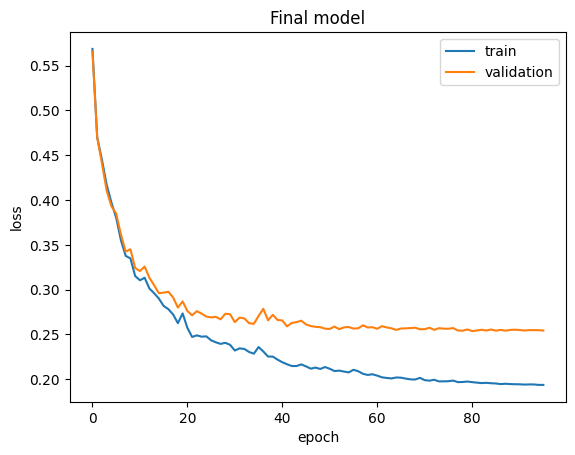

In [ ]:
torch.manual_seed(0)
final = make_net(dropout=0.3)
opt   = torch.optim.Adam(final.parameters(), lr=3e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.5)
h_final = fit(final, opt, epochs=100, sched=sched, patience=15)
show(h_final, "Final model")

In [ ]:
final.eval()
with torch.no_grad():
    probs = torch.softmax(final(Xte_t), dim=1)
conf, pred = probs.max(dim=1)
print("Test accuracy:", round((pred == yte_t).float().mean().item(), 3))


Test accuracy: 0.905


In [ ]:
names = ["Approve", "Review", "Decline"]
actual    = pd.Series(yte_t.numpy()).map(dict(enumerate(names))).rename("actual")
predicted = pd.Series(pred.numpy()).map(dict(enumerate(names))).rename("predicted")
pd.crosstab(actual, predicted).loc[names, names]


predicted,Approve,Review,Decline
actual,,,
Approve,425,25,0
Review,23,223,24
Decline,3,20,257


In [ ]:
for thr in (0.0, 0.7, 0.8, 0.9):
    auto = conf >= thr
    print(f"confidence ≥ {thr}: auto-decide {auto.float().mean():.0%}, "
          f"accuracy on those = {(pred[auto] == yte_t[auto]).float().mean():.1%}")

confidence ≥ 0.0: auto-decide 100%, accuracy on those = 90.5%
confidence ≥ 0.7: auto-decide 88%, accuracy on those = 94.3%
confidence ≥ 0.8: auto-decide 78%, accuracy on those = 96.2%
confidence ≥ 0.9: auto-decide 64%, accuracy on those = 98.7%
